In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:
# Step 1: Load the supplied Kaggle dataset, both in Colab and locally.
from pathlib import Path

candidate_dirs = [
    Path.cwd(),
    Path('/content')
]

# Find both supplied Kaggle CSVs without relying on previous runtime variables.
DATA_DIR = next(
    (directory for directory in candidate_dirs
     if (directory / 'train.csv').is_file()
     and (directory / 'test.csv').is_file()),
    None
)
if DATA_DIR is None:
    raise FileNotFoundError(
        'Could not find train.csv and test.csv together. '
        'Upload both files into the Colab Files panel (/content), '
        'or mount Google Drive and place them in '
        'MyDrive/MAI5043_House_Price_Prediction.'
    )

# All saved charts and CSV outputs use one reproducible results directory.
OUTPUT_DIR = ((Path('/content') if Path('/content').is_dir() else Path.cwd())
              / 'MAI5043_Results')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Preserve literal 'None' (no masonry veneer); treat 'NA' and blanks as missing.
# Pandas' default parser would otherwise combine 864 'None' entries
# with 8 unknown 'NA' entries in MasVnrType.
csv_options = dict(keep_default_na=False, na_values=['NA', ''])
train_df = pd.read_csv(DATA_DIR / 'train.csv', **csv_options)
test_df = pd.read_csv(DATA_DIR / 'test.csv', **csv_options)
print('Dataset directory:', DATA_DIR)
print('Training dataset:', train_df.shape)
print('Testing dataset:', test_df.shape)
print('SalePrice in train:', 'SalePrice' in train_df.columns)
print('SalePrice in Kaggle test:', 'SalePrice' in test_df.columns)
print(train_df.head())
assert train_df.shape == (1460, 81)
assert test_df.shape == (1459, 80)

print('MasVnrType categories (train):')
print(train_df['MasVnrType'].value_counts(dropna=False))
print('Missing MasVnrType values:', train_df['MasVnrType'].isna().sum())


Dataset directory: /content
Training dataset: (1460, 81)
Testing dataset: (1459, 80)
SalePrice in train: True
SalePrice in Kaggle test: False
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4       

In [ ]:

# Identify the target variable
target = "SalePrice"

# Display target variable information
print("Target variable:", target)
print("\nSalePrice statistics:")
print(train_df[target].describe())

# Check missing target values
print("\nMissing SalePrice values:",
      train_df[target].isnull().sum())

Target variable: SalePrice

SalePrice statistics:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Missing SalePrice values: 0


## 2. Exploratory data analysis

In [ ]:

# Step 2.1: Explore dataset information

print("Dataset Shape:", train_df.shape)

print("\nColumn Information:")
train_df.info()

print("\nSummary Statistics:")
print(train_df.describe())

print("\nMissing Values:")
print(train_df.isnull().sum().sort_values(ascending=False).head(15))

print("\nDuplicate Rows:")
print(train_df.duplicated().sum())

print("\nSalePrice Skewness:")
print(train_df["SalePrice"].skew())


Dataset Shape: (1460, 81)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  Overa

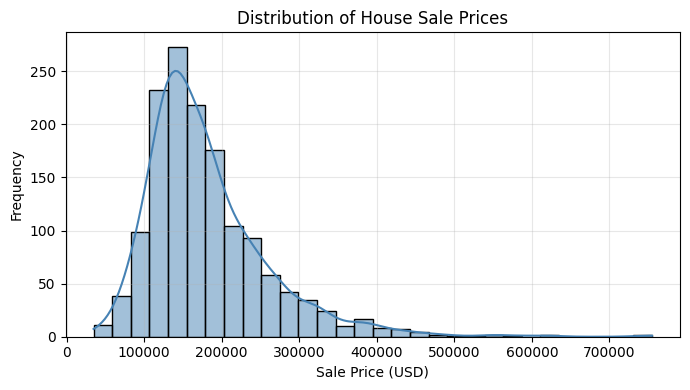

In [ ]:

# Step 2.2: SalePrice Distribution

plt.figure(figsize=(7, 4))

sns.histplot(
    train_df["SalePrice"],
    bins=30,
    kde=True, color="steelblue"
)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price (USD)")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_SalePrice_Distribution.png", dpi=200)
plt.show()


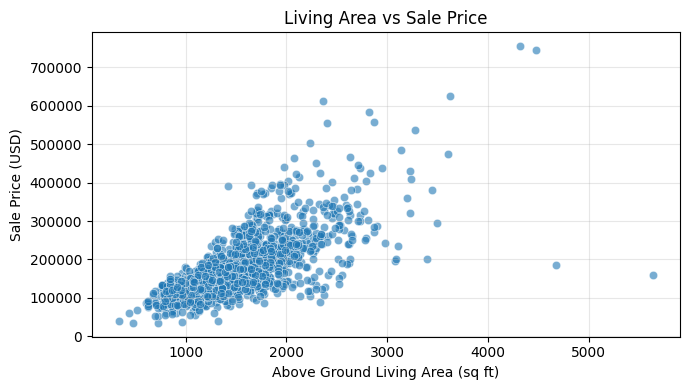

Correlation: 0.7086


In [ ]:

# Step 2.3: Living Area vs SalePrice

plt.figure(figsize=(7, 4))

sns.scatterplot(
    data=train_df,
    x="GrLivArea",
    y="SalePrice",
    alpha=0.6
)

plt.title("Living Area vs Sale Price")
plt.xlabel("Above Ground Living Area (sq ft)")
plt.ylabel("Sale Price (USD)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_LivingArea_vs_SalePrice.png", dpi=200)
plt.show()

# Calculate correlation
correlation = train_df["GrLivArea"].corr(train_df["SalePrice"])
print("Correlation:", round(correlation, 4))


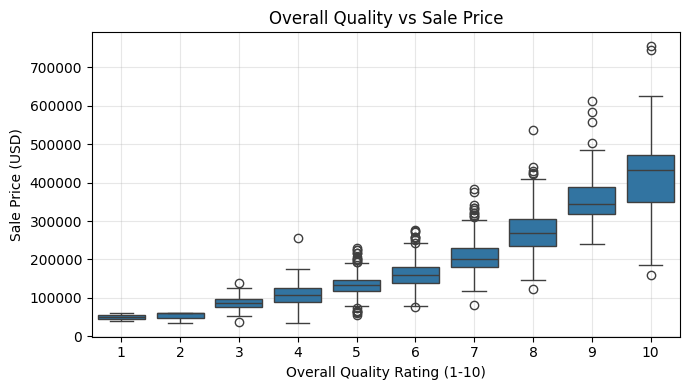

OverallQual
1      50150.0
2      60000.0
3      86250.0
4     108000.0
5     133000.0
6     160000.0
7     200141.0
8     269750.0
9     345000.0
10    432390.0
Name: SalePrice, dtype: float64


In [ ]:

# Step 2.4: Overall Quality vs SalePrice

plt.figure(figsize=(7, 4))

sns.boxplot(
    data=train_df,
    x="OverallQual",
    y="SalePrice"
)

plt.title("Overall Quality vs Sale Price")
plt.xlabel("Overall Quality Rating (1-10)")
plt.ylabel("Sale Price (USD)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_OverallQuality_vs_SalePrice.png", dpi=200)
plt.show()

# Calculate median prices by quality
print(train_df.groupby("OverallQual")["SalePrice"].median())


Top 10 features correlated with SalePrice:
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64


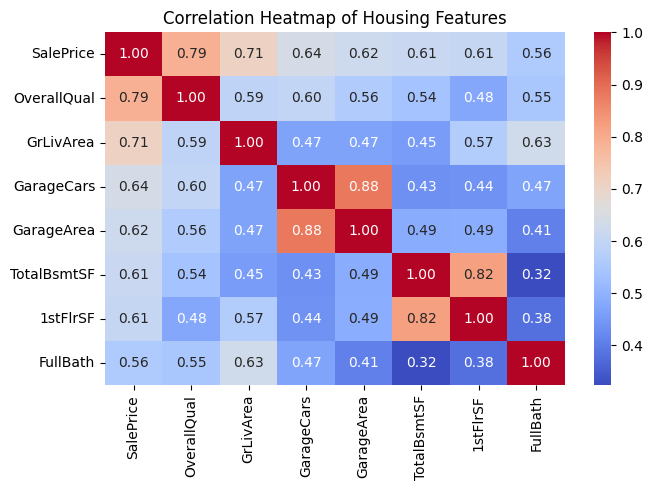

In [ ]:

# Step 2.5: Correlation Analysis

numeric_df = train_df.select_dtypes(include=np.number)

correlations = numeric_df.corr()["SalePrice"].drop(
    ["SalePrice", "Id"], errors="ignore"
).sort_values(ascending=False)

print("Top 10 features correlated with SalePrice:")
print(correlations.head(10))

# Select main variables for heatmap
selected_features = [
    "SalePrice",
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "GarageArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "FullBath"
]

plt.figure(figsize=(7, 5))

sns.heatmap(
    train_df[selected_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap of Housing Features")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_Correlation_Heatmap.png", dpi=200)
plt.show()


Columns with missing values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
FireplaceQu      690
LotFrontage      259
GarageCond        81
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrType         8
MasVnrArea         8
Electrical         1
dtype: int64

Missing percentages:
PoolQC          99.52
MiscFeature     96.30
Alley           93.77
Fence           80.75
FireplaceQu     47.26
LotFrontage     17.74
GarageCond       5.55
GarageType       5.55
GarageYrBlt      5.55
GarageFinish     5.55
GarageQual       5.55
BsmtFinType2     2.60
BsmtExposure     2.60
BsmtCond         2.53
BsmtQual         2.53
BsmtFinType1     2.53
MasVnrType       0.55
MasVnrArea       0.55
Electrical       0.07
dtype: float64


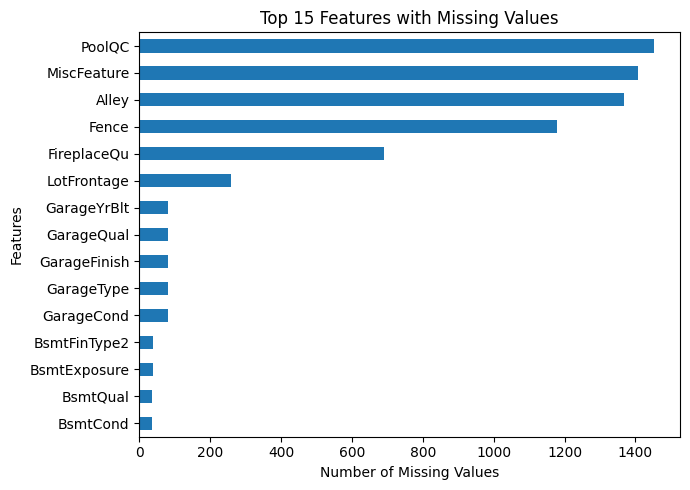

In [ ]:

# Step 2.6: Missing Values Analysis

missing_values = train_df.isnull().sum()
missing_values = missing_values[missing_values > 0]
missing_values = missing_values.sort_values(ascending=False)

print("Columns with missing values:")
print(missing_values)

print("\nMissing percentages:")
print((missing_values / len(train_df) * 100).round(2))

plt.figure(figsize=(7, 5))

missing_values.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Features with Missing Values")
plt.xlabel("Number of Missing Values")
plt.ylabel("Features")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "05_Missing_Values.png", dpi=200)
plt.show()


In [ ]:

# Step 2.7: Inspect potential living-area outliers

large_houses = train_df[
    train_df["GrLivArea"] > 4000
]

print(large_houses[
    ["Id", "GrLivArea", "OverallQual", "SalePrice"]
].sort_values("GrLivArea", ascending=False))


        Id  GrLivArea  OverallQual  SalePrice
1298  1299       5642           10     160000
523    524       4676           10     184750
1182  1183       4476           10     745000
691    692       4316           10     755000


## 3. Preprocessing

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer


In [ ]:
# Step 3.2: Check duplicate records (with and without the unique Id)

duplicates_with_id = train_df.duplicated().sum()
duplicates_without_id = train_df.drop(columns=['Id']).duplicated().sum()

print('Duplicates including Id:', duplicates_with_id)
print('Duplicates excluding Id:', duplicates_without_id)
# No observations are removed: inspection comes before any deletion.


Duplicates including Id: 0
Duplicates excluding Id: 0


In [ ]:

# Step 3.3: Separate features and target

X_all = train_df.drop(columns=["Id", "SalePrice"])
y_all = train_df["SalePrice"]

print("Feature dataset shape:", X_all.shape)
print("Target dataset shape:", y_all.shape)


Feature dataset shape: (1460, 79)
Target dataset shape: (1460,)


In [ ]:

# Step 3.4: Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X_all,
    y_all,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 1168
Testing samples: 292


In [ ]:

# Step 3.5: Define categorical absence features

ABSENCE_CATEGORIES = [
    "Alley",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "PoolQC",
    "Fence",
    "MiscFeature"
]


In [ ]:

# Step 3.6: Feature engineering

def engineer_features(data):
    data = data.copy()

    for col in ABSENCE_CATEGORIES:
        if col in data.columns:
            data[col] = data[col].fillna("None")

    # Keep confirmed masonry veneer absence ("None") separate from unknown ("NA").
    data["MasVnrType"] = data["MasVnrType"].fillna("Unknown")

    data["MSSubClass"] = data["MSSubClass"].astype(str)

    data["HouseAgeAtSale"] = data["YrSold"] - data["YearBuilt"]

    data["YearsSinceRemodel"] = (
        data["YrSold"] - data["YearRemodAdd"]
    )

    data["TotalAboveGroundAndBasementArea"] = (
        data["GrLivArea"] + data["TotalBsmtSF"]
    )

    data["TotalBathrooms"] = (
        data["FullBath"]
        + 0.5 * data["HalfBath"]
        + data["BsmtFullBath"]
        + 0.5 * data["BsmtHalfBath"]
    )

    data["HasGarage"] = (
        data["GarageType"] != "None"
    ).astype(int)

    data["MissingLotFrontage"] = (
        data["LotFrontage"].isna()
    ).astype(int)

    return data


In [ ]:

# Step 3.7: Numerical preprocessing

numeric_pipe = Pipeline([
    ("impute_median", SimpleImputer(
        strategy="median",
        add_indicator=True
    ))
])

# Categorical preprocessing
categorical_pipe = Pipeline([
    ("impute_mode", SimpleImputer(
        strategy="most_frequent"
    )),
    ("one_hot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

# Combine numerical and categorical preprocessing
preprocess = ColumnTransformer([
    (
        "numeric",
        numeric_pipe,
        make_column_selector(dtype_include=np.number)
    ),
    (
        "categorical",
        categorical_pipe,
        make_column_selector(dtype_include=object)
    )
])


In [ ]:

# Step 3.8: Create reusable model pipeline

def create_pipeline(estimator):
    return Pipeline([
        (
            "features",
            FunctionTransformer(
                engineer_features,
                validate=False
            )
        ),
        ("preprocess", preprocess),
        ("model", estimator)
    ])


In [ ]:

# Step 3.9: Verify the preprocessing pipeline

X_train_engineered = engineer_features(X_train)
X_test_engineered = engineer_features(X_test)

X_train_processed = preprocess.fit_transform(
    X_train_engineered
)

X_test_processed = preprocess.transform(
    X_test_engineered
)

print("Original training shape:", X_train.shape)
print("Engineered training shape:", X_train_engineered.shape)
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)


Original training shape: (1168, 79)
Engineered training shape: (1168, 85)
Processed training shape: (1168, 276)
Processed testing shape: (292, 276)


## 4. Regression model

In [ ]:

# Step 4.2: Import regression models

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.base import clone

print("Regression models imported successfully!")


Regression models imported successfully!


In [ ]:

# Step 4.3: Linear Regression reference model

linear_reference = create_pipeline(
    LinearRegression()
)

linear_reference.set_params(
    preprocess=clone(preprocess)
)

linear_reference.fit(X_train, y_train)

print("Linear Regression trained successfully!")


Linear Regression trained successfully!


In [ ]:

# Step 4.4: Original Random Forest Regression model

rf_baseline = create_pipeline(
    RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
)

rf_baseline.set_params(
    preprocess=clone(preprocess)
)

rf_baseline.fit(X_train, y_train)

print("Random Forest Regression trained successfully!")


Random Forest Regression trained successfully!


In [ ]:

# Step 4.5: Generate model predictions

linear_predictions = linear_reference.predict(X_test)

rf_baseline_predictions = rf_baseline.predict(X_test)

print("Linear Regression predictions:")
print(linear_predictions[:5])

print("\nRandom Forest predictions:")
print(rf_baseline_predictions[:5])

print("\nActual prices:")
print(y_test.iloc[:5].values)


Linear Regression predictions:
[163086.871762   353716.47551799  96093.6033915  183357.16351018
 345663.50941255]

Random Forest predictions:
[141839.25  340553.66  113359.29  156845.5   316339.685]

Actual prices:
[154500 325000 115000 159000 315500]


In [ ]:

# Step 4.6: Create prediction comparison table

prediction_comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Linear Regression": linear_predictions,
    "Random Forest": rf_baseline_predictions
})

print(prediction_comparison.head(10))


   Actual Price  Linear Regression  Random Forest
0        154500      163086.871762     141839.250
1        325000      353716.475518     340553.660
2        115000       96093.603391     113359.290
3        159000      183357.163510     156845.500
4        315500      345663.509413     316339.685
5         75500       70179.035456      87178.000
6        311500      244299.995503     203089.010
7        146000      160399.035007     151827.750
8         84500       75052.875524      85794.500
9        135500      147576.421665     130528.420


## 5. Training and evaluation

In [ ]:

# Step 5.1: Import evaluation metrics

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Evaluation metrics imported successfully!")


Evaluation metrics imported successfully!


In [ ]:

# Step 5.2: Create model evaluation function

def evaluate_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }

# Evaluate Linear Regression
linear_metrics = evaluate_model(
    y_test,
    linear_predictions
)

# Evaluate Random Forest
rf_metrics = evaluate_model(
    y_test,
    rf_baseline_predictions
)

print("Linear Regression Results:")
print(linear_metrics)

print("\nRandom Forest Results:")
print(rf_metrics)


Linear Regression Results:
{'MAE': 20692.569271861583, 'MSE': 999288376.1235554, 'RMSE': np.float64(31611.52283778109), 'R2': 0.8697202245209312}

Random Forest Results:
{'MAE': 17433.972363013698, 'MSE': 865449435.1699597, 'RMSE': np.float64(29418.521974598923), 'R2': 0.8871691487698359}


In [ ]:

# Step 5.3: Compare model performance

evaluation_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest Regression"
    ],
    "MAE": [
        linear_metrics["MAE"],
        rf_metrics["MAE"]
    ],
    "MSE": [
        linear_metrics["MSE"],
        rf_metrics["MSE"]
    ],
    "RMSE": [
        linear_metrics["RMSE"],
        rf_metrics["RMSE"]
    ],
    "R2": [
        linear_metrics["R2"],
        rf_metrics["R2"]
    ]
})

print(evaluation_results.round(4))


                      Model         MAE           MSE        RMSE      R2
0         Linear Regression  20692.5693  9.992884e+08  31611.5228  0.8697
1  Random Forest Regression  17433.9724  8.654494e+08  29418.5220  0.8872


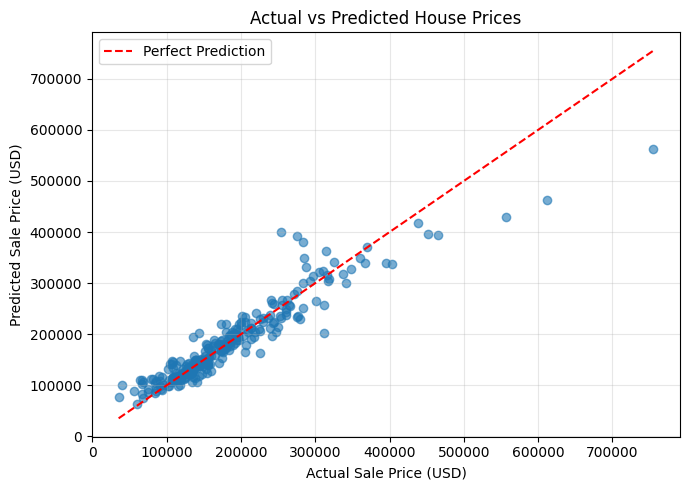

In [ ]:

# Step 5.4: Actual vs Predicted Prices

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    rf_baseline_predictions,
    alpha=0.6
)

min_price = min(y_test.min(), rf_baseline_predictions.min())
max_price = max(y_test.max(), rf_baseline_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Sale Price (USD)")
plt.ylabel("Predicted Sale Price (USD)")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_Actual_vs_Predicted.png", dpi=200)
plt.show()


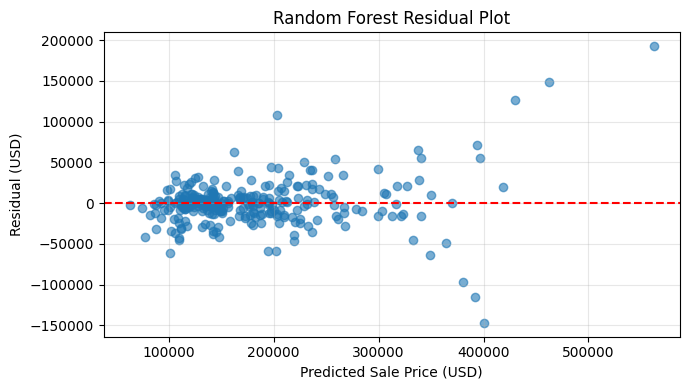

In [ ]:

# Step 5.5: Residual Analysis

residuals = y_test - rf_baseline_predictions

plt.figure(figsize=(7, 4))

plt.scatter(
    rf_baseline_predictions,
    residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Sale Price (USD)")
plt.ylabel("Residual (USD)")
plt.title("Random Forest Residual Plot")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_Residual_Plot.png", dpi=200)
plt.show()


In [ ]:

# Step 5.6: Check overfitting

rf_train_predictions = rf_baseline.predict(X_train)

train_mae = mean_absolute_error(
    y_train,
    rf_train_predictions
)

test_mae = mean_absolute_error(
    y_test,
    rf_baseline_predictions
)

train_r2 = r2_score(
    y_train,
    rf_train_predictions
)

test_r2 = r2_score(
    y_test,
    rf_baseline_predictions
)

print("Training MAE:", round(train_mae, 2))
print("Testing MAE:", round(test_mae, 2))

print("Training R2:", round(train_r2, 4))
print("Testing R2:", round(test_r2, 4))


Training MAE: 6214.5
Testing MAE: 17433.97
Training R2: 0.9801
Testing R2: 0.8872


In [ ]:

# Step 5.7: Save model evaluation results

evaluation_results.to_csv(
    OUTPUT_DIR / "Model_Evaluation_Results.csv",
    index=False
)

prediction_comparison.to_csv(
    OUTPUT_DIR / "House_Price_Prediction_Comparison.csv",
    index=False
)

print("Evaluation results saved successfully!")


Evaluation results saved successfully!


## 6. Optimization with cross-validation

In [ ]:
# Step 6.1: Import cross-validation and optimization utilities
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.base import clone
print('Optimization utilities imported.')


Optimization utilities imported.


In [ ]:
# Step 6.3: Baseline 3-fold cross-validation; X_test remains untouched
baseline_cv_scores = cross_val_score(
    clone(rf_baseline), X_train, y_train,
    cv=3, scoring='neg_root_mean_squared_error', n_jobs=1
)
baseline_cv_rmse = -baseline_cv_scores
print('Baseline CV RMSE by fold:', baseline_cv_rmse)
print('Original mean CV RMSE: $%0.2f' % baseline_cv_rmse.mean())
print('Original CV std: $%0.2f' % baseline_cv_rmse.std())


Baseline CV RMSE by fold: [29796.21717671 32421.62953113 24273.19376126]
Original mean CV RMSE: $28830.35
Original CV std: $3395.97


In [ ]:
# Step 6.4: Focused, reproducible search; explicitly includes the baseline.
# 2 x 2 x 2 = 8 configurations; 200 trees / leaf1 / max_features1.0 is the baseline.
param_grid = {
    'model__n_estimators': [200, 300],
    'model__max_depth': [None],
    'model__min_samples_split': [2],
    'model__min_samples_leaf': [1, 2],
    'model__max_features': [0.75, 1.0]
}
print('Candidate configurations:', 8)


Candidate configurations: 8


In [ ]:
# Step 6.5: Grid search with 3-fold CV (all on training set only)
rf_search = GridSearchCV(
    estimator=clone(rf_baseline),
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=3,
    n_jobs=1,
    verbose=1,
    return_train_score=True,
    refit=True
)
rf_search.fit(X_train, y_train)
print('Validation-based model search completed.')


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Validation-based model search completed.


In [ ]:
# Step 6.6: Compare original model vs best candidate on identical CV folds
print('Best parameters:', rf_search.best_params_)
print('Selected CV RMSE: $%0.2f' % (-rf_search.best_score_))
print('Original CV RMSE: $%0.2f' % baseline_cv_rmse.mean())
cv_gain = baseline_cv_rmse.mean() - (-rf_search.best_score_)
print('CV RMSE reduction: $%0.2f' % cv_gain)
print('Positive reduction = better CV performance; zero = baseline retained.')


Best parameters: {'model__max_depth': None, 'model__max_features': 0.75, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 300}
Selected CV RMSE: $28426.11
Original CV RMSE: $28830.35
CV RMSE reduction: $404.23
Positive reduction = better CV performance; zero = baseline retained.


   param_model__n_estimators  param_model__min_samples_leaf  \
3                        300                              2   
7                        300                              2   
1                        300                              1   
2                        200                              2   
0                        200                              1   
6                        200                              2   
5                        300                              1   
4                        200                              1   

   param_model__max_features   CV RMSE  rank_test_score  
3                       0.75  28426.11                1  
7                       1.00  28529.34                2  
1                       0.75  28554.66                3  
2                       0.75  28575.06                4  
0                       0.75  28582.53                5  
6                       1.00  28677.01                6  
5                       1.

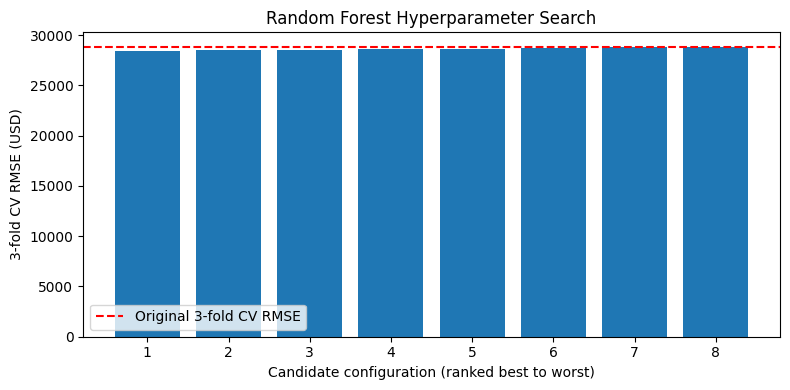

In [ ]:
# Step 6.7: Search results and hyperparameter ranking
results = pd.DataFrame(rf_search.cv_results_)
tuning_summary = results[[
    'param_model__n_estimators', 'param_model__max_depth',
    'param_model__min_samples_split', 'param_model__min_samples_leaf',
    'param_model__max_features', 'mean_test_score',
    'std_test_score', 'mean_train_score', 'rank_test_score'
]].copy()
tuning_summary['CV RMSE'] = -tuning_summary['mean_test_score']
tuning_summary = tuning_summary.sort_values('rank_test_score')
print(tuning_summary[['param_model__n_estimators',
                      'param_model__min_samples_leaf',
                      'param_model__max_features', 'CV RMSE', 'rank_test_score']].round(2))
tuning_summary.to_csv(OUTPUT_DIR / 'Random_Forest_Tuning_Results.csv', index=False)

# Show every candidate's validation RMSE, not only the winner.
plt.figure(figsize=(8, 4))
plt.bar(range(1, len(tuning_summary)+1), tuning_summary['CV RMSE'])
plt.axhline(baseline_cv_rmse.mean(), color='red', ls='--', label='Original 3-fold CV RMSE')
plt.xlabel('Candidate configuration (ranked best to worst)')
plt.ylabel('3-fold CV RMSE (USD)')
plt.title('Random Forest Hyperparameter Search')
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '08_CV_Hyperparameter_Comparison.png', dpi=180)
plt.show()


In [ ]:
# Step 6.8: Evaluate CV-selected model on the held-out test split ONCE
rf_optimized = rf_search.best_estimator_
optimized_predictions = rf_optimized.predict(X_test)
optimized_metrics = evaluate_model(y_test, optimized_predictions)
print('Selected model test metrics:', optimized_metrics)


Selected model test metrics: {'MAE': 17224.72963815504, 'MSE': 853619317.0670084, 'RMSE': np.float64(29216.76431549203), 'R2': 0.8887114714538263}


In [ ]:

# Step 6.9: Compare original and optimized models

optimization_comparison = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2"],
    "Original Random Forest": [
        rf_metrics["MAE"],
        rf_metrics["MSE"],
        rf_metrics["RMSE"],
        rf_metrics["R2"]
    ],
    "Optimized Random Forest": [
        optimized_metrics["MAE"],
        optimized_metrics["MSE"],
        optimized_metrics["RMSE"],
        optimized_metrics["R2"]
    ]
})

print(optimization_comparison.round(4))


  Metric  Original Random Forest  Optimized Random Forest
0    MAE            1.743397e+04             1.722473e+04
1    MSE            8.654494e+08             8.536193e+08
2   RMSE            2.941852e+04             2.921676e+04
3     R2            8.872000e-01             8.887000e-01


In [ ]:
# Step 6.10: Negative percentages mean deterioration, not improvement.
mae_improvement = 100 * (rf_metrics['MAE'] - optimized_metrics['MAE']) / rf_metrics['MAE']
rmse_improvement = 100 * (rf_metrics['RMSE'] - optimized_metrics['RMSE']) / rf_metrics['RMSE']
r2_change = optimized_metrics['R2'] - rf_metrics['R2']
print('Test MAE reduction (%):', round(mae_improvement, 2))
print('Test RMSE reduction (%):', round(rmse_improvement, 2))
print('Test R2 change:', round(r2_change, 4))
print('These are descriptive test comparisons, NOT hyperparameter selection criteria.')


Test MAE reduction (%): 1.2
Test RMSE reduction (%): 0.69
Test R2 change: 0.0015
These are descriptive test comparisons, NOT hyperparameter selection criteria.


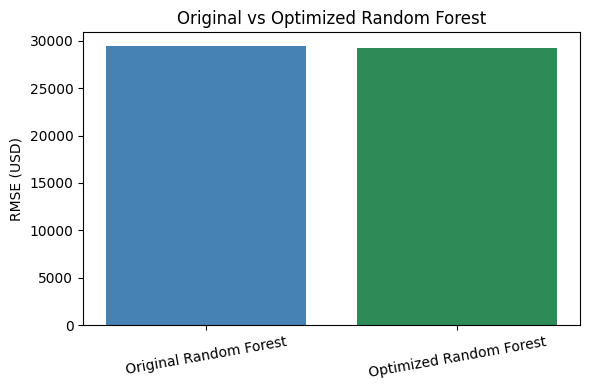

In [ ]:

# Step 6.11: Compare RMSE visually

models = [
    "Original Random Forest",
    "Optimized Random Forest"
]

rmse_values = [
    rf_metrics["RMSE"],
    optimized_metrics["RMSE"]
]

plt.figure(figsize=(6, 4))

plt.bar(
    models,
    rmse_values,
    color=["steelblue", "seagreen"]
)

plt.ylabel("RMSE (USD)")
plt.title("Original vs Optimized Random Forest")

plt.xticks(rotation=10)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "08_Original_vs_Optimized_RMSE.png",
    dpi=200
)

plt.show()


In [ ]:

# Step 6.12: Save optimization results

optimization_comparison.to_csv(
    OUTPUT_DIR / "Model_Optimization_Comparison.csv",
    index=False
)

print("Optimization results saved successfully!")


Optimization results saved successfully!


## 7. Critical analysis

In [ ]:

# Step 7.1: Extract feature importance

# Get the trained preprocessing step
fitted_preprocessor = rf_optimized.named_steps["preprocess"]

# Get the trained Random Forest
fitted_forest = rf_optimized.named_steps["model"]

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract feature importance scores
importance_scores = fitted_forest.feature_importances_

# Create feature importance table
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

# Sort from highest to lowest
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
print(feature_importance_df.head(15))


Top 15 Important Features:
                                     Feature  Importance
37  numeric__TotalAboveGroundAndBasementArea    0.352895
2                       numeric__OverallQual    0.351782
14                        numeric__GrLivArea    0.027368
12                         numeric__2ndFlrSF    0.021170
24                       numeric__GarageCars    0.020124
4                         numeric__YearBuilt    0.016870
35                   numeric__HouseAgeAtSale    0.013759
7                        numeric__BsmtFinSF1    0.012693
38                   numeric__TotalBathrooms    0.012496
1                           numeric__LotArea    0.012186
25                       numeric__GarageArea    0.010541
5                      numeric__YearRemodAdd    0.008255
36                numeric__YearsSinceRemodel    0.008126
10                      numeric__TotalBsmtSF    0.008068
0                       numeric__LotFrontage    0.007471


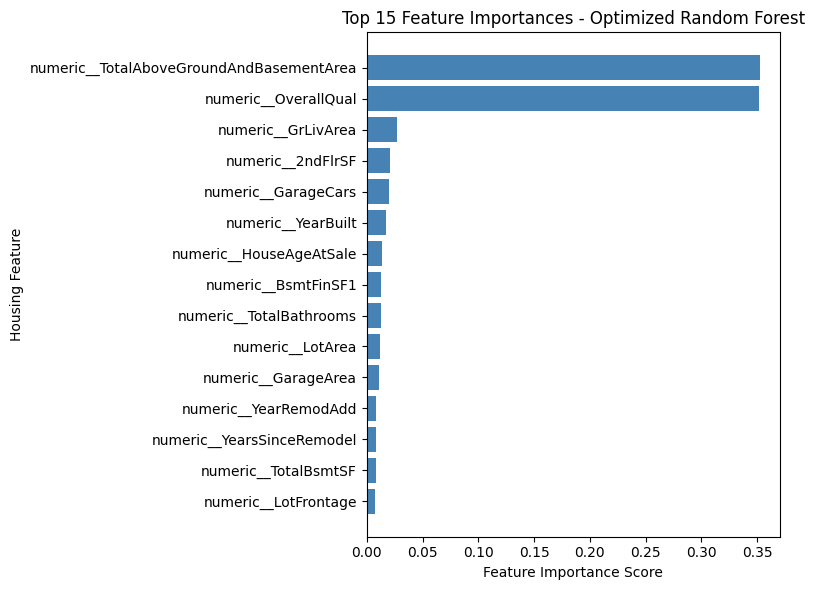

In [ ]:

# Step 7.2: Plot top 15 feature importances

top_features = feature_importance_df.head(15)

plt.figure(figsize=(8, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1],
    color="steelblue"
)

plt.xlabel("Feature Importance Score")
plt.ylabel("Housing Feature")
plt.title("Top 15 Feature Importances - Optimized Random Forest")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "09_Feature_Importance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


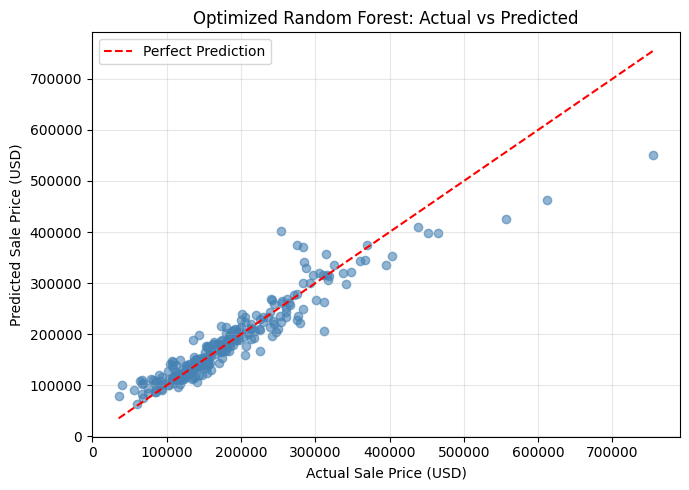

In [ ]:

# Step 7.3: Optimized Model - Actual vs Predicted

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    optimized_predictions,
    alpha=0.6,
    color="steelblue"
)

min_price = min(
    y_test.min(),
    optimized_predictions.min()
)

max_price = max(
    y_test.max(),
    optimized_predictions.max()
)

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Sale Price (USD)")
plt.ylabel("Predicted Sale Price (USD)")
plt.title("Optimized Random Forest: Actual vs Predicted")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "10_Optimized_Actual_vs_Predicted.png",
    dpi=200
)

plt.show()


In [ ]:
# Step 7.4: Error analysis by price quartile, including percentage error
error_analysis = pd.DataFrame({
    'ActualPrice': y_test.values,
    'PredictedPrice': optimized_predictions
})
error_analysis['Residual'] = error_analysis['ActualPrice'] - error_analysis['PredictedPrice']
error_analysis['AbsoluteError'] = error_analysis['Residual'].abs()
error_analysis['AbsolutePercentageError'] = 100 * error_analysis['AbsoluteError'] / error_analysis['ActualPrice']
error_analysis['PriceGroup'] = pd.qcut(
    error_analysis['ActualPrice'], q=4,
    labels=['Q1 - Lowest','Q2 - Lower Middle','Q3 - Upper Middle','Q4 - Highest']
)
price_group_results = error_analysis.groupby('PriceGroup', observed=True).agg(
    NumberOfHouses=('ActualPrice','size'),
    MeanActualPrice=('ActualPrice','mean'),
    MAE=('AbsoluteError','mean'),
    MeanAbsolutePercentageError=('AbsolutePercentageError','mean')
)
print(price_group_results.round(2))


                   NumberOfHouses  MeanActualPrice       MAE  \
PriceGroup                                                     
Q1 - Lowest                    75        101607.41  13824.83   
Q2 - Lower Middle              71        139672.63   8854.94   
Q3 - Upper Middle              73        179376.36  12926.64   
Q4 - Highest                   73        295745.73  33156.34   

                   MeanAbsolutePercentageError  
PriceGroup                                      
Q1 - Lowest                              17.66  
Q2 - Lower Middle                         6.31  
Q3 - Upper Middle                         7.24  
Q4 - Highest                             10.37  


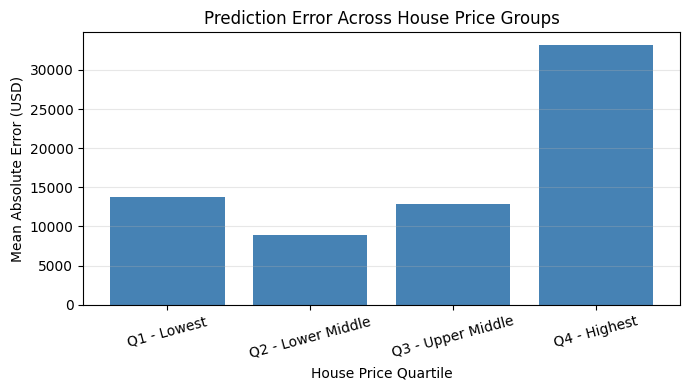

In [ ]:

# Step 7.5: Plot error by price range

plt.figure(figsize=(7, 4))

plt.bar(
    price_group_results.index.astype(str),
    price_group_results["MAE"],
    color="steelblue"
)

plt.title("Prediction Error Across House Price Groups")
plt.xlabel("House Price Quartile")
plt.ylabel("Mean Absolute Error (USD)")

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "11_Price_Group_Error.png",
    dpi=200
)

plt.show()


In [ ]:

# Step 7.6: Compare optimized training and testing results

optimized_train_predictions = rf_optimized.predict(X_train)

optimized_train_metrics = evaluate_model(
    y_train,
    optimized_train_predictions
)

optimized_test_metrics = evaluate_model(
    y_test,
    optimized_predictions
)

generalization_comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Training": [
        optimized_train_metrics["MAE"],
        optimized_train_metrics["RMSE"],
        optimized_train_metrics["R2"]
    ],
    "Testing": [
        optimized_test_metrics["MAE"],
        optimized_test_metrics["RMSE"],
        optimized_test_metrics["R2"]
    ]
})

print(generalization_comparison.round(4))


  Metric    Training     Testing
0    MAE   6942.8235  17224.7296
1   RMSE  13057.3223  29216.7643
2     R2      0.9714      0.8887


In [ ]:
# Step 7.7: Optional predictions for Kaggle's unlabelled test.csv
X_kaggle_test = test_df.drop(columns=['Id'])
kaggle_predictions = rf_optimized.predict(X_kaggle_test)
kaggle_submission = pd.DataFrame({'Id': test_df['Id'], 'SalePrice': kaggle_predictions})
kaggle_submission.to_csv(OUTPUT_DIR / 'Kaggle_House_Price_Submission.csv', index=False)
print('Kaggle submission rows:', len(kaggle_submission))
print(kaggle_submission.head())


Kaggle submission rows: 1459
     Id      SalePrice
0  1461  122371.085593
1  1462  162895.186458
2  1463  184931.306151
3  1464  185591.641127
4  1465  204246.189421


In [ ]:

# Step 7.8: Save final analysis tables

feature_importance_df.to_csv(
    OUTPUT_DIR / "Feature_Importance_Results.csv",
    index=False
)

price_group_results.to_csv(
    OUTPUT_DIR / "Price_Group_Error_Results.csv"
)

error_analysis.to_csv(
    OUTPUT_DIR / "Final_Prediction_Error_Analysis.csv",
    index=False
)

generalization_comparison.to_csv(
    OUTPUT_DIR / "Generalization_Comparison.csv",
    index=False
)

print("All final analysis files saved successfully!")


All final analysis files saved successfully!


In [ ]:
# Step 8: Final reproducibility audit and bundle results
from zipfile import ZipFile

summary_table = pd.DataFrame([
    {'Model': 'Linear Regression', **linear_metrics},
    {'Model': 'Original Random Forest', **rf_metrics},
    {'Model': 'CV-selected Random Forest', **optimized_metrics}
])
summary_table.to_csv(OUTPUT_DIR / 'Final_Model_Metrics.csv', index=False)
print('=== REPORT-READY MODEL METRICS ===')
print(summary_table.round(3).to_string(index=False))
print('Baseline CV RMSE: $%0.2f' % baseline_cv_rmse.mean())
print('Selected model CV RMSE: $%0.2f' % (-rf_search.best_score_))
print('Best parameters:', rf_search.best_params_)
print('CV-selected RF improves test RMSE:', optimized_metrics['RMSE'] < rf_metrics['RMSE'])
print('CV-selected RF improves CV RMSE:', -rf_search.best_score_ < baseline_cv_rmse.mean() - 1e-7)

archive_path = Path('MAI5043_Results_Bundle.zip')
with ZipFile(archive_path, 'w') as archive:
    for f in sorted(OUTPUT_DIR.iterdir()):
        if f.suffix.lower() in {'.png', '.csv'}:
            archive.write(f, arcname=f.name)
print('Saved %d result files under %s' % (len(list(OUTPUT_DIR.iterdir())), OUTPUT_DIR))
print('Results ZIP:', archive_path.resolve())


=== REPORT-READY MODEL METRICS ===
                    Model       MAE          MSE      RMSE    R2
        Linear Regression 20692.569 9.992884e+08 31611.523 0.870
   Original Random Forest 17433.972 8.654494e+08 29418.522 0.887
CV-selected Random Forest 17224.730 8.536193e+08 29216.764 0.889
Baseline CV RMSE: $28830.35
Selected model CV RMSE: $28426.11
Best parameters: {'model__max_depth': None, 'model__max_features': 0.75, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 300}
CV-selected RF improves test RMSE: True
CV-selected RF improves CV RMSE: True
Saved 22 result files under /content/MAI5043_Results
Results ZIP: /content/MAI5043_Results_Bundle.zip
